## Appendix

In [1]:
from scipy.stats import chi2, norm
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families.links import Probit
from scipy.special import logit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import root_scalar

pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

### Task 1

#### (a)

In [2]:
df1 = pd.read_csv('dataset/menarche.txt', sep=' ')
print(df1.head())

     Age  Total  Menarche
0   9.21    376         0
1  10.21    200         0
2  10.58     93         0
3  10.83    120         2
4  11.08     90         2


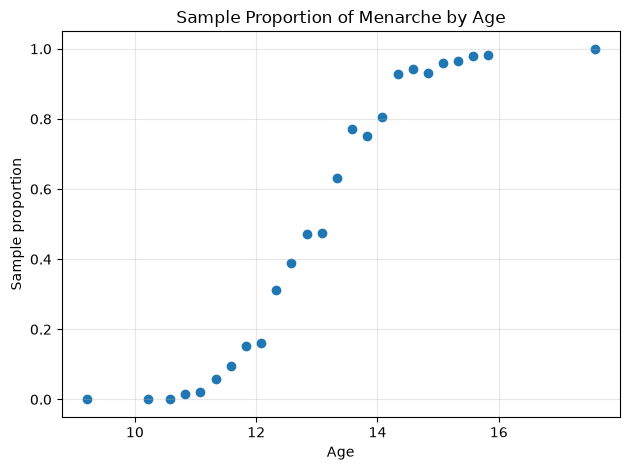

In [3]:
df1['prop'] = df1['Menarche'] / df1['Total']

plt.scatter(df1['Age'], df1['prop'])
plt.xlabel('Age')
plt.ylabel('Sample proportion')
plt.title('Sample Proportion of Menarche by Age')
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

#### (b)

In [4]:
df1['fail'] = df1['Total'] - df1['Menarche']

fm_logit1 = glm('Menarche + fail ~ Age', df1, family=Binomial()).fit()
fm_logit2 = update_glm(fm_logit1, add='I(Age**2)')
fm_logit3 = update_glm(fm_logit2, add='I(Age**3)')
fm_logit4 = update_glm(fm_logit3, add='I(Age**4)')

In [5]:
print(anova_nested(fm_logit1, fm_logit2, fm_logit3, fm_logit4))

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1       23.0   26.703452  NaN       NaN       NaN
Model 2       22.0   23.202068  1.0  3.501384  0.061318
Model 3       21.0   15.044541  1.0  8.157527  0.004288
Model 4       20.0   14.654940  1.0  0.389601  0.532509


In [6]:
fm_probit1 = glm('Menarche + fail ~ Age', df1, family=Binomial(link=Probit())).fit()
fm_probit2 = update_glm(fm_probit1, add='I(Age**2)')
fm_probit3 = update_glm(fm_probit2, add='I(Age**3)')

In [7]:
print(anova_nested(fm_probit1, fm_probit2, fm_probit3))

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1       23.0   22.887433  NaN       NaN       NaN
Model 2       22.0   15.148752  1.0  7.738681  0.005405
Model 3       21.0   14.092838  1.0  1.055914  0.304149


In [8]:
print("Logit + Age**3:", fm_logit3.aic)
print("Probit + Age**2:", fm_probit2.aic)

Logit + Age**3: 107.09634405709603
Probit + Age**2: 105.20055453268716


In [9]:
print(fm_probit2.params)

Intercept     -20.183212
Age             2.185452
I(Age ** 2)    -0.048391
dtype: float64


#### (c)

##### (i)

In [10]:
df1['log_age_9'] = np.log(df1['Age'] - 9)
df1['log_18_age'] = np.log(18 - df1['Age'])
fm_log = glm('Menarche + fail ~ log_age_9 + log_18_age', df1, family=Binomial()).fit()
print(fm_log.summary2(),'\n')

                Results: Generalized linear model
Model:              GLM                  Method:         IRLS    
Model Family:       Binomial             AIC:            104.7103
Link Function:      Logit                BIC:            108.3670
Dependent Variable: ['Menarche', 'fail'] Log-Likelihood: -49.355 
Date:               2026-10-06 16:12     LL-Null:        -1889.0 
No. Observations:   25                   Deviance:       14.659  
Df Model:           2                    Pearson chi2:   13.1    
Df Residuals:       22                   Scale:          1.0000  
------------------------------------------------------------------
               Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
------------------------------------------------------------------
Intercept     -2.5935    2.0240  -1.2814  0.2001  -6.5605   1.3735
log_age_9      4.4347    0.6568   6.7521  0.0000   3.1474   5.7220
log_18_age    -2.1467    0.7370  -2.9129  0.0036  -3.5911  -0.7023
 



In [11]:
print(fm_log.params)

Intercept    -2.593525
log_age_9     4.434702
log_18_age   -2.146731
dtype: float64


In [12]:
print("Probit + Age**2:", fm_probit2.aic)
print("Transformed-age Logistic:", fm_log.aic)

Probit + Age**2: 105.20055453268716
Transformed-age Logistic: 104.71032568377802


##### (ii)

In [13]:
def f(x):
    pred_df = pd.DataFrame({'log_age_9': [np.log(x-9)], 'log_18_age': [np.log(18-x)]}) 
    pred_value = fm_log.predict(pred_df, which='linear')[0]
    return pred_value - logit(p)

p = 0.9
P90 = root_scalar(f, bracket=[9, 18], method='brentq')
print(P90.root)

14.443652010598106


C:\Users\YuxinLi\AppData\Local\Temp\ipykernel_29808\404491753.py:2: RuntimeWarning: divide by zero encountered in log
  pred_df = pd.DataFrame({'log_age_9': [np.log(x-9)], 'log_18_age': [np.log(18-x)]})
C:\Users\YuxinLi\AppData\Local\Temp\ipykernel_29808\404491753.py:2: RuntimeWarning: divide by zero encountered in log
  pred_df = pd.DataFrame({'log_age_9': [np.log(x-9)], 'log_18_age': [np.log(18-x)]})


In [14]:
x = P90.root
beta = np.array(fm_log.params)
dm = beta[1]/(x-9)-beta[2]/(18-x)  # denominator
h = np.array([-1/dm, -np.log(x-9)/dm, -np.log(18-x)/dm])
sd_x = np.sqrt(h @ np.array(fm_log.cov_params()) @ h)
print(sd_x)

0.07129974813890703


### Task 2

#### (a)

In [15]:
df2 = pd.read_csv('dataset/satisfaction.csv')
print(df2.head())

   Satisfied  Notsatisfied Gender Race  Age Region
0        288           177      M    W  <35     NE
1         90            45      M    W  <35     MA
2        226           128      M    W  <35      S
3        285           179      M    W  <35     MW
4        270           180      M    W  <35     NW


In [16]:
df2['Gender'] = pd.Categorical(df2['Gender'], categories=['F', 'M'], ordered=True)
df2['Race'] = pd.Categorical(df2['Race'], categories=['O', 'W'], ordered=True)
df2['Age'] = pd.Categorical(df2['Age'], categories=['<35', '35-44', '>44'], ordered=True)
df2['Region'] = pd.Categorical(df2['Region'], categories=['MA', 'NE', 'S', 'MW', 'NW', 'SW', 'P'], ordered=True)

print(df2.info())

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Satisfied     84 non-null     int64   
 1   Notsatisfied  84 non-null     int64   
 2   Gender        84 non-null     category
 3   Race          84 non-null     category
 4   Age           84 non-null     category
 5   Region        84 non-null     category
dtypes: category(4), int64(2)
memory usage: 2.5 KB
None


In [18]:
fmfull = glm('Satisfied + Notsatisfied ~ Gender * Race * Age * Region', df2, family=Binomial()).fit()

print(drop1_glm(fmfull))

                        Df      Deviance         AIC        LRT  Pr(>Chi)
<none>                      4.304939e-09  533.009216                     
Gender:Race:Age:Region  12  1.995873e+01  528.967950  19.958734  0.067871


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linea

In [19]:
fm2 = update_glm(fmfull, drop='Gender:Race:Age:Region')
print(drop1_glm(fm2))

                    Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                  19.958734  528.967950                     
Gender:Race:Age      2  23.737710  528.746926   3.778976  0.151149
Gender:Race:Region   6  23.171554  520.180771   3.212821  0.781701
Gender:Age:Region   12  39.906394  524.915611  19.947661  0.068083
Race:Age:Region     12  39.734348  524.743565  19.775615  0.071451


In [20]:
fm2 = update_glm(fm2, drop='Gender:Race:Region')
print(drop1_glm(fm2))

                   Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                 23.171554  520.180771                     
Gender:Race:Age     2  27.563138  520.572354   4.391584   0.11127
Gender:Age:Region  12  43.429816  516.439032  20.258262  0.062356
Race:Age:Region    12  42.341849  515.351065  19.170295  0.084501


In [21]:
fm2 = update_glm(fm2, drop='Gender:Race:Age')
print(drop1_glm(fm2))

                   Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                 27.563138  520.572354                     
Gender:Race         1  35.680163  526.689379   8.117025  0.004385
Gender:Age:Region  12  48.025277  517.034494  20.462139  0.058833
Race:Age:Region    12  45.858581  514.867798  18.295443   0.10701


In [22]:
fm2 = update_glm(fm2, drop='Race:Age:Region')
print(drop1_glm(fm2))

                   Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                 45.858581  514.867798                     
Gender:Race         1  53.437687  520.446903   7.579105  0.005905
Race:Age            2  47.088807  512.098023   1.230225   0.54058
Race:Region         6  50.142851  507.152067    4.28427  0.638267
Gender:Age:Region  12  66.031779  511.040995  20.173198   0.06388


In [23]:
fm2 = update_glm(fm2, drop='Race:Region')
print(drop1_glm(fm2))

                   Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                 50.142851  507.152067                     
Gender:Race         1  57.262244  512.271460   7.119393  0.007625
Race:Age            2  51.036427  504.045643   0.893576   0.63968
Gender:Age:Region  12  70.414110  503.423326  20.271259  0.062126


In [24]:
fm2 = update_glm(fm2, drop='Race:Age')
print(drop1_glm(fm2))

                   Df   Deviance         AIC        LRT  Pr(>Chi)
<none>                 51.036427  504.045643                     
Gender:Race         1  58.476925  509.486141   7.440498  0.006377
Gender:Age:Region  12  71.037436  500.046653  20.001009  0.067067


In [25]:
fm2 = update_glm(fm2, drop='Gender:Age:Region')
print(drop1_glm(fm2))

               Df   Deviance         AIC       LRT  Pr(>Chi)
<none>             71.037436  500.046653                    
Gender:Race     1  77.790092  504.799308  6.752655  0.009361
Gender:Age      2  76.852847  501.862063  5.815411  0.054601
Gender:Region   6  74.197320  491.206536  3.159884  0.788529
Age:Region     12  79.019943  484.029159  7.982507  0.786496


In [26]:
fm2 = update_glm(fm2, drop='Gender:Region')
print(drop1_glm(fm2))

             Df   Deviance         AIC       LRT  Pr(>Chi)
<none>           74.197320  491.206536                    
Gender:Race   1  81.995960  497.005176   7.79864  0.005229
Gender:Age    2  79.785846  492.795062  5.588526   0.06116
Age:Region   12  81.967599  474.976816  7.770279  0.802815


In [27]:
fm2 = update_glm(fm2, drop='Age:Region')
print(drop1_glm(fm2))

            Df    Deviance         AIC        LRT  Pr(>Chi)
<none>           81.967599  474.976816                     
Region       6  120.229073  501.238289  38.261474  0.000001
Gender:Race  1   89.561766  480.570983   7.594167  0.005856
Gender:Age   2   87.941035  476.950251   5.973435  0.050453


In [28]:
fm2 = update_glm(fm2, drop='Gender:Age')
print(drop1_glm(fm2))

            Df    Deviance         AIC        LRT  Pr(>Chi)
<none>           87.941035  476.950251                     
Age          2  138.242651  523.251867  50.301616       0.0
Region       6  126.030905  503.040122  38.089871  0.000001
Gender:Race  1   97.516346  484.525562   9.575312  0.001972


In [29]:
print(fm2.summary2(),'\n')

                    Results: Generalized linear model
Model:              GLM                           Method:         IRLS    
Model Family:       Binomial                      AIC:            476.9503
Link Function:      Logit                         BIC:            506.1201
Dependent Variable: ['Satisfied', 'Notsatisfied'] Log-Likelihood: -226.48 
Date:               2026-10-06 16:36              LL-Null:        -284.58 
No. Observations:   84                            Deviance:       87.941  
Df Model:           11                            Pearson chi2:   84.5    
Df Residuals:       72                            Scale:          1.0000  
---------------------------------------------------------------------------
                        Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
---------------------------------------------------------------------------
Intercept               0.4310    0.1217   3.5399  0.0004   0.1924   0.6696
Gender[T.M]             0.4903    0.1112  

In [30]:
print(np.exp(-0.4364))
print(np.exp(fm2.params[5:11]))

0.646359130567587
Region[T.NE]    0.646381
Region[T.S]     0.770106
Region[T.MW]    0.705075
Region[T.NW]    0.731126
Region[T.SW]    0.862342
Region[T.P]     0.975774
dtype: float64


#### (b)

##### (i)

In [31]:
fm = glm('Satisfied + Notsatisfied ~ Gender + Race + Age + Region', df2, family=Binomial(link=Probit())).fit()

print(fm.summary2(),'\n')

                    Results: Generalized linear model
Model:              GLM                           Method:         IRLS    
Model Family:       Binomial                      AIC:            484.7811
Link Function:      Probit                        BIC:            511.5201
Dependent Variable: ['Satisfied', 'Notsatisfied'] Log-Likelihood: -231.39 
Date:               2026-10-06 16:42              LL-Null:        -284.58 
No. Observations:   84                            Deviance:       97.772  
Df Model:           10                            Pearson chi2:   93.4    
Df Residuals:       73                            Scale:          1.0000  
----------------------------------------------------------------------------
                    Coef.    Std.Err.      z      P>|z|     [0.025    0.975]
----------------------------------------------------------------------------
Intercept           0.3634     0.0676    5.3745   0.0000    0.2309    0.4959
Gender[T.M]         0.1107     0.0294 

In [32]:
beta = fm.params.values
cov_beta = fm.cov_params().values

# Male, White, Age <35, Region MA
x = np.array([1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0])

p_hat = norm.cdf(x @ beta)
h = norm.pdf(x @ beta) * x

se_p = np.sqrt(h @ cov_beta @ h)

ci = (
    p_hat - norm.ppf(0.975) * se_p,
    p_hat + norm.ppf(0.975) * se_p
)

print("p^ =", p_hat)
print("SE(p) =", se_p)
print("95% CI =", ci)

p^ = 0.6833784214815958
SE(p) = 0.020843065037679298
95% CI = (np.float64(0.6425267646803183), np.float64(0.7242300782828732))


In [33]:
eta = x @ beta
se_eta = np.sqrt(x @ cov_beta @ x)

eta_lower = eta - 1.96 * se_eta
eta_upper = eta + 1.96 * se_eta

print(eta_lower, eta_upper)

ci_transformed = (
    norm.cdf(eta_lower),
    norm.cdf(eta_upper)
)

print("Link-scale CI:", ci_transformed)

0.3624179154108527 0.5919162275293712
Link-scale CI: (np.float64(0.6414801231869482), np.float64(0.7230466566424082))


##### (ii)

In [34]:
print("Residual deviance:", fm.deviance, "df:", fm.df_resid)
p_dev = chi2.sf(fm.deviance, fm.df_resid)

print(p_dev)

Residual deviance: 97.77187502880088 df: 73
0.028111308365711272


In [35]:
print(fm.deviance / fm.df_resid)

print("Pearson X2:", fm.pearson_chi2)
print(fm.pearson_chi2 / fm.df_resid)

1.3393407538191902
Pearson X2: 93.37796976513586
1.2791502707552858
